In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams

* fig3 A、B：绘制训练集、评估集阳性肽段长度分布

In [8]:
def plot_bar(df,output_file):
    # 计算每个肽段的长度
    df["length"] = df["peptide"].str.len()
    df_fit=df[df["length"]<15] 
    # 统计不同长度的数量
    length_counts = df_fit["length"].value_counts().sort_index()
    # 设置字体（如使用中文可指定字体文件）
    # 例如 font = font_manager.FontProperties(fname="/System/Library/Fonts/STHeiti Light.ttc")
    # 若仅想设置英文字体，可指定 rcParams
    rcParams['font.family'] = 'Arial'     # 设置字体族
    rcParams['font.size'] = 12            # 设置字体大小

    # 绘图
    plt.figure(figsize=(4,5))  # 指定图形大小 (width, height)
    plt.bar(length_counts.index, length_counts.values, width=0.8, color='skyblue', edgecolor='skyblue')

    # 添加标题和标签
    #plt.title("Peptide Length Distribution", fontsize=14, weight='bold')
    plt.xlabel("Peptide Length", fontsize=12)
    plt.ylabel("Count", fontsize=12)
    # 美化布局
    plt.tight_layout()
    plt.savefig(output_file, dpi=300)
    plt.show()

/tmp/ipykernel_4120394/3271266791.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["length"] = df["peptide"].str.len()


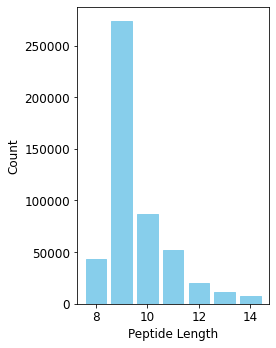

In [ ]:
train_file="Table_MHCI_LKMHCpandata_Trim_final.tsv"
df_train=pd.read_csv(train_file,sep=",")
df_train.columns=['peptide','label','HLA']
df_train_fit=df_train[df_train["label"]==1]
plot_bar(df_train_fit,'Fig3_train_peptide_length_distribution.svg')

/tmp/ipykernel_4120394/3271266791.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["length"] = df["peptide"].str.len()


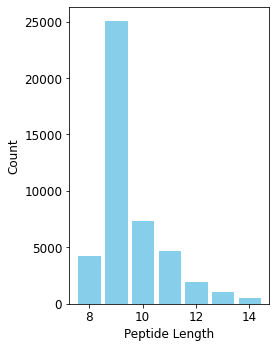

In [ ]:
eval_file="Evaluation_data_set_from_netMHCpan_trim.csv"
df_eval=pd.read_csv(eval_file,sep="\t")
df_eval_fit=df_eval[df_eval["measurement_value"]==1]
plot_bar(df_eval_fit,'Fig3_eval_peptide_length_distribution.svg')